# E-commerce Sales and Customer Analysis

**Business question:** How is the business performing, where does revenue come from, do customers come back, and what should the business do next?

**Data:** Olist, a Brazilian online marketplace. About 100,000 orders placed between 2016 and 2018, stored in PostgreSQL as 7 linked tables.

**How this notebook works:** every number comes from a SQL query in the `sql/` folder. The notebook runs each query, shows the SQL, charts the result and states the finding. Python is used only for charts.

| Section | Question |
|---|---|
| 1. Data quality | Can the data be trusted, and what needs cleaning? |
| 2. Sales performance | How much are we selling and is it growing? |
| 3. Customer retention | Do customers come back? |
| 4. Customer segments | Who are the valuable customers? |
| 5. Delivery and reviews | Does delivery affect satisfaction? |
| 6. Findings and recommendations | What should the business do? |

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns

from src.db import query, read_queries

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
FIGURES = "../reports/figures/"
BLUE, GREY, RED, AMBER = "#2563eb", "#9ca3af", "#dc2626", "#f59e0b"

QUERIES = {}
for file in ["00_data_quality_checks.sql", "03_sales_performance.sql", "04_customer_retention.sql",
             "05_customer_segments.sql", "06_delivery_and_reviews.sql"]:
    QUERIES.update(read_queries(file))


def run(name: str, show_sql: bool = True) -> pd.DataFrame:
    """Print a named query from the sql/ folder and return its result."""
    if show_sql:
        print(QUERIES[name].strip())
    return query(QUERIES[name])


print(len(QUERIES), "queries loaded")

28 queries loaded


## 1. Data quality

Before analysing anything, check the raw tables. Each check below led to a cleaning decision.

In [2]:
run("order_status")

-- Check 2. What states can an order be in?
-- Decision: only 'delivered' orders count as sales.
SELECT
    order_status,
    COUNT(*)                                            AS orders,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)  AS share_pct
FROM orders
GROUP BY order_status
ORDER BY orders DESC;


,order_status,orders,share_pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


**Decision 1: only delivered orders count as sales.** 97% of orders are delivered. The rest were cancelled, unavailable or still in progress, so they never became revenue.

-- Check 3. Is every month complete?
-- Decision: 2016 and Sep-Oct 2018 hold almost no orders, so the
-- analysis window is Jan 2017 to Aug 2018.
SELECT
    DATE_TRUNC('month', order_purchase_timestamp)::date AS order_month,
    COUNT(*)                                            AS orders
FROM orders
GROUP BY 1
ORDER BY 1;


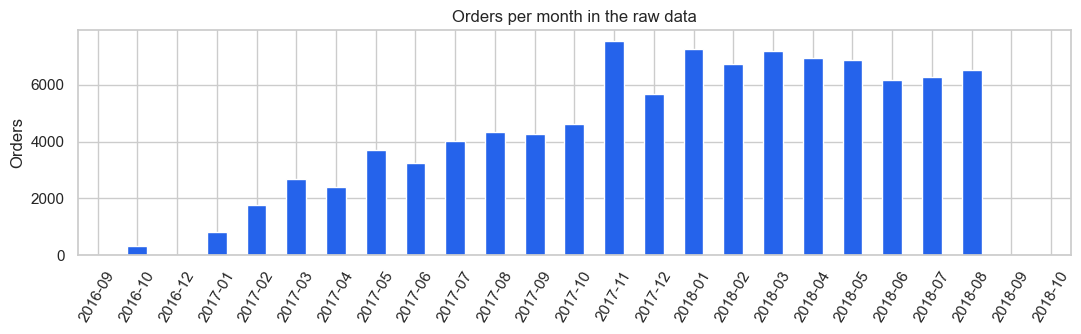

In [3]:
monthly_raw = run("orders_per_month")
ax = monthly_raw.plot.bar(x="order_month", y="orders", legend=False, color=BLUE, figsize=(11, 3.5))
ax.set(title="Orders per month in the raw data", xlabel="", ylabel="Orders")
ax.set_xticklabels([d.strftime("%Y-%m") for d in pd.to_datetime(monthly_raw["order_month"])], rotation=60)
plt.tight_layout()
plt.show()

**Decision 2: analyse January 2017 to August 2018.** The months at both ends hold only a handful of orders (4 in September 2016, 16 in September 2018). They are incomplete, and including them would make growth figures meaningless.

In [4]:
run("customer_identity")

-- Check 4. Does customer_id identify a person?
-- Decision: no. There are as many customer_ids as orders. The real
-- person is customer_unique_id.
SELECT
    COUNT(*)                            AS customer_rows,
    COUNT(DISTINCT customer_id)         AS distinct_customer_id,
    COUNT(DISTINCT customer_unique_id)  AS distinct_customer_unique_id
FROM customers;


,customer_rows,distinct_customer_id,distinct_customer_unique_id
0,99441,99441,96096


**Decision 3: identify customers by `customer_unique_id`.** There are 99,441 values of `customer_id`, exactly one per order, but only 96,096 real people. Counting repeat purchases with `customer_id` would wrongly show that nobody ever buys twice.

In [5]:
run("missing_values")

-- Check 5. Where are values missing?
-- COUNT(column) skips NULLs, so COUNT(*) - COUNT(column) counts them.
SELECT 'orders.order_delivered_customer_date (all orders)' AS field,
       COUNT(*) - COUNT(order_delivered_customer_date)     AS missing
FROM orders
UNION ALL
SELECT 'orders.order_delivered_customer_date (delivered only)',
       COUNT(*) - COUNT(order_delivered_customer_date)
FROM orders WHERE order_status = 'delivered'
UNION ALL
SELECT 'products.product_category',
       COUNT(*) - COUNT(product_category)
FROM products
UNION ALL
SELECT 'orders with no items',
       COUNT(*)
FROM orders o
WHERE NOT EXISTS (SELECT 1 FROM order_items i WHERE i.order_id = o.order_id)
UNION ALL
SELECT 'delivered orders with no review',
       COUNT(*)
FROM orders o
WHERE o.order_status = 'delivered'
  AND NOT EXISTS (SELECT 1 FROM reviews r WHERE r.order_id = o.order_id);


,field,missing
0,products.product_category,610
1,orders.order_delivered_customer_date (all orders),2965
2,orders.order_delivered_customer_date (delivere...,8
3,delivered orders with no review,646
4,orders with no items,775


In [6]:
run("duplicate_reviews")

-- Check 6. Can an order have more than one review?
-- Decision: yes, so the most recent review per order is used.
SELECT
    reviews_per_order,
    COUNT(*) AS orders
FROM (
    SELECT order_id, COUNT(*) AS reviews_per_order
    FROM reviews
    GROUP BY order_id
) t
GROUP BY reviews_per_order
ORDER BY reviews_per_order;


,reviews_per_order,orders
0,1,98126
1,2,543
2,3,4


**Decision 4: handle the gaps instead of deleting rows.**

- 610 products have no category. They are labelled `unknown` so their revenue is still counted.
- 8 delivered orders have no delivery date. They are kept, and left out of delivery-time averages only.
- 646 delivered orders have no review. They are kept, and left out of review averages only.
- 547 orders have more than one review. The most recent review is used.

All of these decisions are implemented once, in `sql/02_views.sql`. Every query below reads from those clean views.

## 2. Sales performance

In [7]:
run("kpi_summary").T.rename(columns={0: "value"})

-- Q1. What are the headline numbers for the business?
SELECT
    COUNT(*)                                   AS orders,
    COUNT(DISTINCT customer_unique_id)         AS customers,
    ROUND(SUM(revenue), 0)                     AS revenue,
    ROUND(AVG(revenue), 2)                     AS avg_order_value,
    ROUND(SUM(items)::numeric / COUNT(*), 2)   AS items_per_order,
    ROUND(AVG(delivery_days), 1)               AS avg_delivery_days,
    ROUND(AVG(review_score), 2)                AS avg_review_score
FROM v_orders;


,value
orders,"96,211.00"
customers,"93,104.00"
revenue,"13,181,027.00"
avg_order_value,137.00
items_per_order,1.14
avg_delivery_days,12.50
avg_review_score,4.16


In 20 months the marketplace delivered **96,211 orders** to **93,104 customers**, worth **R$13.2 million**. The average order is R$137 and holds just over one item.

-- Q2. How has revenue changed month by month?
-- LAG() fetches the previous month's revenue so growth can be calculated.
-- SUM() OVER (ORDER BY ...) gives a running total.
WITH monthly AS (
    SELECT
        order_month,
        COUNT(*)      AS orders,
        SUM(revenue)  AS revenue
    FROM v_orders
    GROUP BY order_month
)
SELECT
    order_month,
    orders,
    ROUND(revenue, 0)                                     AS revenue,
    ROUND(revenue / orders, 2)                            AS avg_order_value,
    ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY order_month))
          / LAG(revenue) OVER (ORDER BY order_month), 1)  AS growth_pct,
    ROUND(SUM(revenue) OVER (ORDER BY order_month), 0)    AS running_revenue
FROM monthly
ORDER BY order_month;


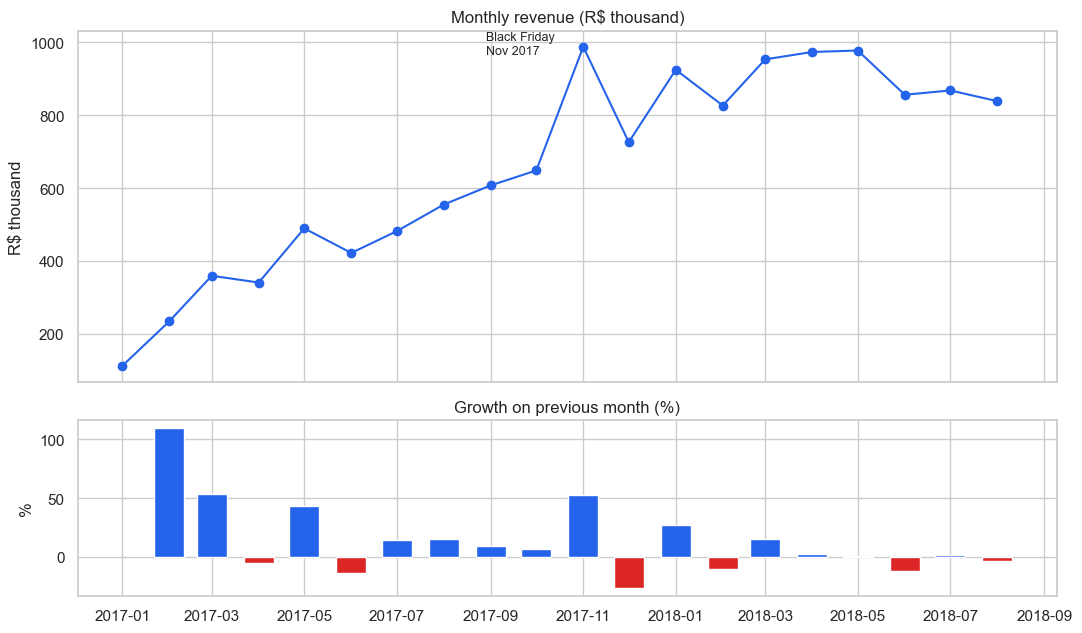

,order_month,orders,revenue,avg_order_value,growth_pct,running_revenue
0,2017-01-01,750,"111,798.00",149.06,NaN,"111,798.00"
1,2017-02-01,1653,"234,223.00",141.70,109.50,"346,022.00"
2,2017-03-01,2546,"359,199.00",141.08,53.40,"705,221.00"
3,2017-04-01,2303,"340,670.00",147.92,-5.20,"1,045,890.00"
4,2017-05-01,3546,"489,338.00",138.00,43.60,"1,535,229.00"
5,2017-06-01,3135,"421,923.00",134.58,-13.80,"1,957,152.00"
6,2017-07-01,3872,"481,605.00",124.38,14.10,"2,438,756.00"
7,2017-08-01,4193,"554,700.00",132.29,15.20,"2,993,456.00"
8,2017-09-01,4150,"607,400.00",146.36,9.50,"3,600,856.00"
9,2017-10-01,4478,"648,248.00",144.76,6.70,"4,249,103.00"


In [8]:
monthly = run("monthly_revenue")
monthly["order_month"] = pd.to_datetime(monthly["order_month"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[2, 1])
ax1.plot(monthly["order_month"], monthly["revenue"] / 1000, marker="o", color=BLUE)
ax1.set(title="Monthly revenue (R$ thousand)", ylabel="R$ thousand")
peak = monthly.loc[monthly["revenue"].idxmax()]
ax1.annotate("Black Friday\nNov 2017", (peak["order_month"], peak["revenue"] / 1000),
             textcoords="offset points", xytext=(-70, -5), fontsize=9)
ax2.bar(monthly["order_month"], monthly["growth_pct"], width=20,
        color=[BLUE if v >= 0 else RED for v in monthly["growth_pct"].fillna(0)])
ax2.set(title="Growth on previous month (%)", ylabel="%")
plt.tight_layout()
plt.savefig(FIGURES + "monthly_revenue.png", dpi=130)
plt.show()
monthly

**Findings**

- **2017 was a year of fast growth.** Monthly revenue rose from R$112 thousand in January to R$726 thousand in December.
- **November 2017 was the peak**, at R$988 thousand, up 52% on October. That is Black Friday.
- **Growth stopped in 2018.** Every month from January to August 2018 sits between R$826 thousand and R$978 thousand, with no upward trend.

Comparing each month with the same month a year earlier removes seasonality:

In [9]:
run("year_over_year")

-- Q3. Compared with the same month a year earlier, how much did we grow?
-- Comparing January with January removes the effect of seasonality.
-- LAG(revenue, 12) looks back twelve rows, which is twelve months.
WITH monthly AS (
    SELECT order_month, SUM(revenue) AS revenue
    FROM v_orders
    GROUP BY order_month
),
compared AS (
    SELECT
        order_month,
        revenue,
        LAG(revenue, 12) OVER (ORDER BY order_month) AS revenue_last_year
    FROM monthly
)
SELECT
    order_month,
    ROUND(revenue_last_year, 0)                                      AS revenue_last_year,
    ROUND(revenue, 0)                                                AS revenue_this_year,
    ROUND(100.0 * (revenue - revenue_last_year) / revenue_last_year, 0) AS yoy_growth_pct
FROM compared
WHERE revenue_last_year IS NOT NULL
ORDER BY order_month;


,order_month,revenue_last_year,revenue_this_year,yoy_growth_pct
0,2018-01-01,"111,798.00","924,645.00",727.00
1,2018-02-01,"234,223.00","826,437.00",253.00
2,2018-03-01,"359,199.00","953,356.00",165.00
3,2018-04-01,"340,670.00","973,534.00",186.00
4,2018-05-01,"489,338.00","977,545.00",100.00
5,2018-06-01,"421,923.00","856,078.00",103.00
6,2018-07-01,"481,605.00","867,953.00",80.00
7,2018-08-01,"554,700.00","838,577.00",51.00


Year-on-year growth is still positive but falling fast: from over 700% in January 2018 to 51% in August 2018. The business is maturing, and it can no longer rely on new customers alone to grow.

-- Q4. Which product categories bring in the most revenue?
-- The cumulative share shows how few categories make up most of sales.
WITH by_category AS (
    SELECT
        product_category,
        COUNT(*)                  AS items_sold,
        COUNT(DISTINCT order_id)  AS orders,
        SUM(price)                AS revenue
    FROM v_order_items
    GROUP BY product_category
)
SELECT
    RANK() OVER (ORDER BY revenue DESC)                              AS rank,
    product_category,
    items_sold,
    ROUND(revenue, 0)                                                AS revenue,
    ROUND(revenue / items_sold, 2)                                   AS avg_item_price,
    ROUND(100.0 * revenue / SUM(revenue) OVER (), 1)                 AS revenue_share_pct,
    ROUND(100.0 * SUM(revenue) OVER (ORDER BY revenue DESC)
          / SUM(revenue) OVER (), 1)                                 AS cumulative_share_pct
FROM by_category
ORDER BY revenue DESC
LIMIT 15;


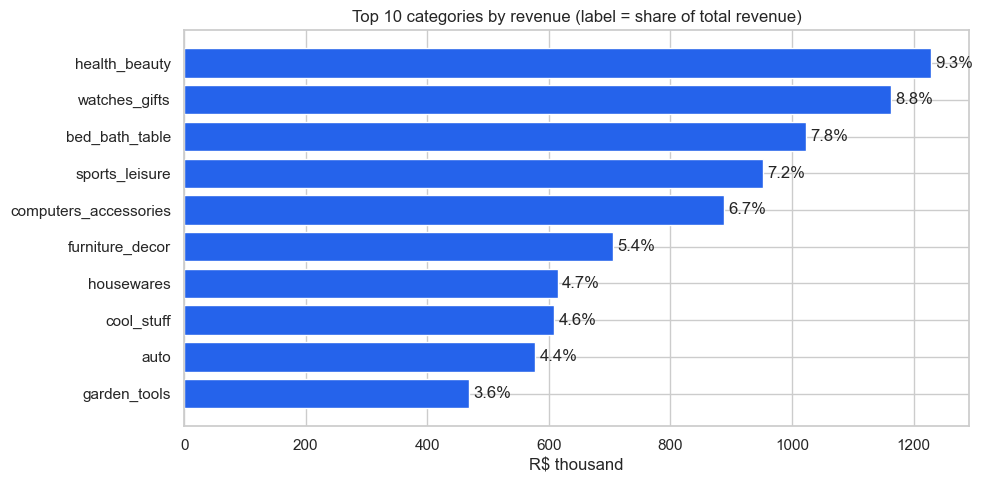

,rank,product_category,items_sold,revenue,avg_item_price,revenue_share_pct,cumulative_share_pct
0,1,health_beauty,9422,"1,229,558.00",130.50,9.30,9.30
1,2,watches_gifts,5855,"1,163,466.00",198.71,8.80,18.20
2,3,bed_bath_table,10945,"1,022,956.00",93.46,7.80,25.90
3,4,sports_leisure,8414,"952,840.00",113.24,7.20,33.10
4,5,computers_accessories,7632,"888,056.00",116.36,6.70,39.90
5,6,furniture_decor,8095,"706,237.00",87.24,5.40,45.20
6,7,housewares,6783,"614,342.00",90.57,4.70,49.90
7,8,cool_stuff,3711,"609,158.00",164.15,4.60,54.50
8,9,auto,4132,"577,838.00",139.84,4.40,58.90
9,10,garden_tools,4263,"469,135.00",110.05,3.60,62.50


In [10]:
categories = run("top_categories")
fig, ax = plt.subplots(figsize=(10, 5))
top = categories.head(10).iloc[::-1]
bars = ax.barh(top["product_category"], top["revenue"] / 1000, color=BLUE)
ax.bar_label(bars, labels=[f"{s}%" for s in top["revenue_share_pct"]], padding=3)
ax.set(title="Top 10 categories by revenue (label = share of total revenue)", xlabel="R$ thousand")
plt.tight_layout()
plt.savefig(FIGURES + "top_categories.png", dpi=130)
plt.show()
categories

In [11]:
run("category_concentration")

-- Q5. How many categories does it take to reach 80% of revenue?
WITH by_category AS (
    SELECT product_category, SUM(price) AS revenue
    FROM v_order_items
    GROUP BY product_category
),
ranked AS (
    SELECT
        product_category,
        SUM(revenue) OVER (ORDER BY revenue DESC) / SUM(revenue) OVER () AS cumulative_share
    FROM by_category
)
SELECT
    COUNT(*) FILTER (WHERE cumulative_share <= 0.80) + 1  AS categories_for_80_pct,
    COUNT(*)                                              AS total_categories
FROM ranked;


,categories_for_80_pct,total_categories
0,18,74


**Findings**

- **Health and beauty** is the largest category (9.3% of revenue), followed by watches and gifts, and bed, bath and table.
- **Revenue is concentrated.** The top 5 categories bring in 40% of revenue, and **18 of 74 categories make up 80%**.
- Watches and gifts has the highest average item price in the top 10 (R$199), so it earns second place with far fewer items sold.

In [12]:
run("revenue_by_state")

-- Q6. Which states do customers buy from?
SELECT
    customer_state,
    COUNT(*)                                             AS orders,
    ROUND(SUM(revenue), 0)                               AS revenue,
    ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS revenue_share_pct,
    ROUND(AVG(revenue), 2)                               AS avg_order_value,
    ROUND(AVG(freight), 2)                               AS avg_freight
FROM v_orders
GROUP BY customer_state
ORDER BY revenue DESC
LIMIT 10;


,customer_state,orders,revenue,revenue_share_pct,avg_order_value,avg_freight
0,SP,40406,"5,055,587.00",38.40,125.12,17.33
1,RJ,12310,"1,751,434.00",13.30,142.28,23.96
2,MG,11319,"1,548,207.00",11.70,136.78,23.48
3,RS,5328,"726,374.00",5.50,136.33,24.81
4,PR,4903,"664,048.00",5.00,135.44,23.49
5,SC,3537,"504,774.00",3.80,142.71,24.84
6,BA,3253,"493,339.00",3.70,151.66,29.97
7,DF,2074,"295,455.00",2.20,142.46,23.85
8,GO,1950,"281,932.00",2.10,144.58,26.27
9,ES,1992,"267,784.00",2.00,134.43,24.54


**Finding:** sales are concentrated in the south-east. **São Paulo (SP) alone is 38% of revenue**, and SP, Rio de Janeiro (RJ) and Minas Gerais (MG) together are 63%. Freight is also cheapest in SP (R$17 per order against R$23 to R$30 in the other large states), because most sellers are based there.

In [13]:
run("weekday_pattern")

-- Q7. On which days of the week do customers order?
SELECT
    EXTRACT(ISODOW FROM order_date)::int                 AS weekday_number,
    TO_CHAR(order_date, 'Day')                           AS weekday,
    COUNT(*)                                             AS orders,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)   AS share_pct
FROM v_orders
GROUP BY 1, 2
ORDER BY 1;


,weekday_number,weekday,orders,share_pct
0,1,Monday,15660,16.30
1,2,Tuesday,15449,16.10
2,3,Wednesday,15041,15.60
3,4,Thursday,14281,14.80
4,5,Friday,13646,14.20
5,6,Saturday,10519,10.90
6,7,Sunday,11615,12.10


In [14]:
run("payment_methods")

-- Q8. How do customers pay?
-- Joins the raw payments table to the clean orders view.
SELECT
    p.payment_type,
    COUNT(DISTINCT p.order_id)                                   AS orders,
    ROUND(SUM(p.payment_value), 0)                               AS amount_paid,
    ROUND(100.0 * SUM(p.payment_value) / SUM(SUM(p.payment_value)) OVER (), 1) AS share_pct,
    ROUND(AVG(p.payment_installments), 1)                        AS avg_installments
FROM payments p
JOIN v_orders o ON o.order_id = p.order_id
GROUP BY p.payment_type
ORDER BY amount_paid DESC;


,payment_type,orders,amount_paid,share_pct,avg_installments
0,credit_card,74095,"12,063,101.00",78.50,3.50
1,boleto,19140,"2,762,301.00",18.00,1.00
2,voucher,3670,"342,295.00",2.20,1.00
3,debit_card,1483,"208,179.00",1.40,1.00


**Findings**

- Customers order mostly on weekdays. Monday is the busiest day (16.3%) and Saturday the quietest (10.9%).
- **Credit cards account for 78.5% of payments**, split into 3.5 instalments on average. Boleto (a Brazilian bank slip) is 18%.

## 3. Customer retention

Winning a new customer usually costs more than selling again to an existing one. So the key question is: do customers come back?

In [15]:
repeat = run("repeat_rate")
repeat

-- Q9. How many customers buy more than once?
SELECT
    CASE WHEN orders = 1 THEN '1 order'
         WHEN orders = 2 THEN '2 orders'
         ELSE '3 or more orders' END                             AS customer_group,
    COUNT(*)                                                     AS customers,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)           AS customer_share_pct,
    ROUND(SUM(revenue), 0)                                       AS revenue,
    ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1)   AS revenue_share_pct,
    ROUND(AVG(revenue), 2)                                       AS revenue_per_customer
FROM v_customers
GROUP BY 1
ORDER BY 1;


,customer_group,customers,customer_share_pct,revenue,revenue_share_pct,revenue_per_customer
0,1 order,90315,97.00,"12,455,672.00",94.50,137.91
1,2 orders,2562,2.80,"628,326.00",4.80,245.25
2,3 or more orders,227,0.20,"97,029.00",0.70,427.44


**This is the most important finding in the analysis: 97% of customers ordered exactly once.** Only 3% (2,789 customers) came back.

Those who do come back are worth more: a customer with two orders brings R$245 on average, against R$138 for a one-time customer.

-- Q10. Each month, how much revenue comes from new and from returning customers?
-- customer_order_number = 1 marks a customer's first ever order.
SELECT
    order_month,
    COUNT(*) FILTER (WHERE customer_order_number = 1)            AS new_customer_orders,
    COUNT(*) FILTER (WHERE customer_order_number > 1)            AS returning_customer_orders,
    ROUND(SUM(revenue) FILTER (WHERE customer_order_number > 1), 0) AS returning_revenue,
    ROUND(100.0 * SUM(revenue) FILTER (WHERE customer_order_number > 1)
          / SUM(revenue), 1)                                     AS returning_revenue_pct
FROM v_orders
GROUP BY order_month
ORDER BY order_month;


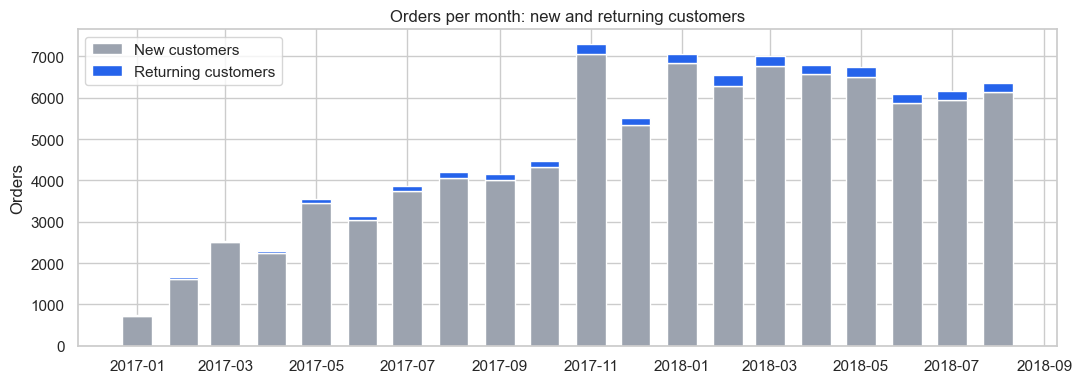

,order_month,new_customer_orders,returning_customer_orders,returning_revenue,returning_revenue_pct
12,2018-01-01,6843,226,"28,964.00",3.10
13,2018-02-01,6288,267,"30,006.00",3.60
14,2018-03-01,6775,228,"26,637.00",2.80
15,2018-04-01,6582,216,"27,698.00",2.80
16,2018-05-01,6508,241,"32,994.00",3.40
17,2018-06-01,5879,220,"28,562.00",3.30
18,2018-07-01,5949,210,"26,295.00",3.00
19,2018-08-01,6144,207,"25,927.00",3.10


In [16]:
nvr = run("new_vs_returning")
nvr["order_month"] = pd.to_datetime(nvr["order_month"])
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(nvr["order_month"], nvr["new_customer_orders"], width=20, color=GREY, label="New customers")
ax.bar(nvr["order_month"], nvr["returning_customer_orders"], width=20,
       bottom=nvr["new_customer_orders"], color=BLUE, label="Returning customers")
ax.set(title="Orders per month: new and returning customers", ylabel="Orders")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES + "new_vs_returning.png", dpi=130)
plt.show()
nvr.tail(8)

**Finding:** returning customers bring in only about **3% of revenue in any month**. Nearly all sales come from people buying for the first time. That explains the flat revenue in 2018: when growth in new customers slowed, there was no base of repeat buyers to keep revenue rising.

### Cohort analysis

A cohort is the group of customers who placed their first order in the same month. The table shows what share of each cohort ordered again 1, 2, 3 ... months later.

-- Q11. Of the customers who first bought in a given month, what share
--      ordered again 1, 2, 3 ... months later?
-- A cohort is the group of customers who placed their first order in
-- the same month. months_since_first = 0 is that first month.
WITH activity AS (
    SELECT DISTINCT
        c.cohort_month,
        o.customer_unique_id,
        (EXTRACT(YEAR FROM AGE(o.order_month, c.cohort_month)) * 12
         + EXTRACT(MONTH FROM AGE(o.order_month, c.cohort_month)))::int AS months_since_first
    FROM v_orders o
    JOIN v_customers c USING (customer_unique_id)
),
cohort_size AS (
    SELECT cohort_month, COUNT(*) AS customers
    FROM v_customers
    GROUP BY cohort_month
)
SELECT
    a.cohort_month,
    s.customers                                                  AS cohort_customers,
    a.months_since_first,
    COUNT(*)                                                     AS active_customers,
    ROUND(100.0 * COUNT(*) / s.customers, 2)                     AS retention_pct


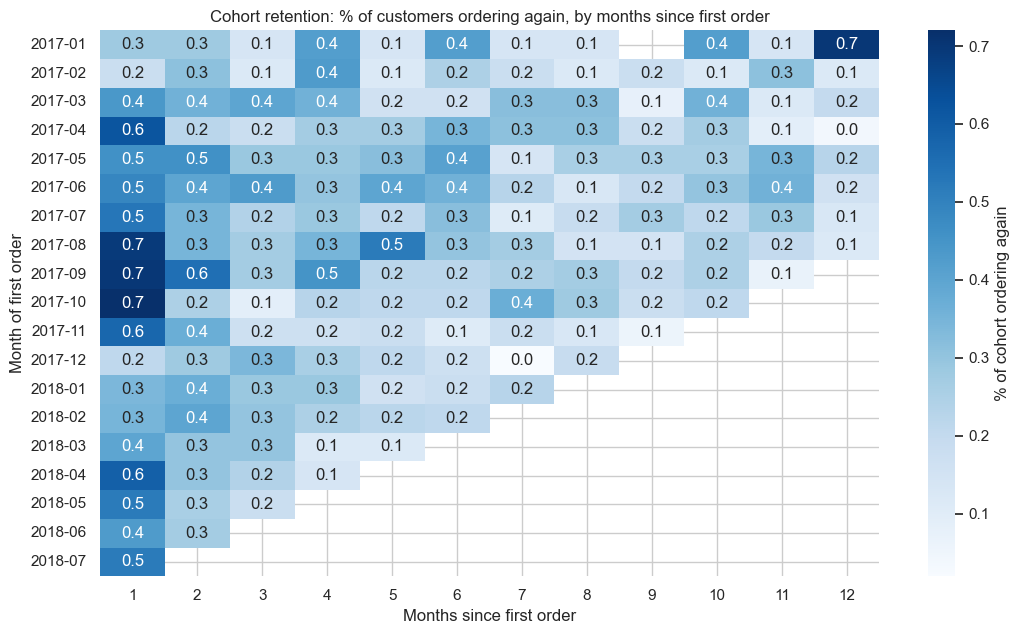

Highest retention in any cell: 0.72%


In [17]:
cohorts = run("cohort_retention")
matrix = cohorts[cohorts["months_since_first"] > 0].pivot(
    index="cohort_month", columns="months_since_first", values="retention_pct")
matrix.index = [pd.to_datetime(d).strftime("%Y-%m") for d in matrix.index]

plt.figure(figsize=(11, 6.5))
sns.heatmap(matrix, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of cohort ordering again"})
plt.title("Cohort retention: % of customers ordering again, by months since first order")
plt.xlabel("Months since first order")
plt.ylabel("Month of first order")
plt.tight_layout()
plt.savefig(FIGURES + "cohort_retention.png", dpi=130)
plt.show()
print(f"Highest retention in any cell: {matrix.max().max():.2f}%")

**Finding:** in every cohort, well under 1% of customers order again in any later month. There is no cohort that behaves better than the others, so this is not a problem that started recently. It is how the marketplace has always worked.

In [18]:
run("time_to_second_order")

-- Q12. When customers do come back, how long does it take?
-- LEAD() fetches the date of each customer's next order.
WITH gaps AS (
    SELECT
        customer_order_number,
        LEAD(order_date) OVER (PARTITION BY customer_unique_id
                               ORDER BY customer_order_number) - order_date AS days_to_next
    FROM v_orders
),
first_gap AS (
    SELECT days_to_next
    FROM gaps
    WHERE customer_order_number = 1 AND days_to_next IS NOT NULL
)
SELECT
    CASE WHEN days_to_next = 0    THEN '1. Same day'
         WHEN days_to_next <= 30  THEN '2. Within 30 days'
         WHEN days_to_next <= 90  THEN '3. 31 to 90 days'
         WHEN days_to_next <= 180 THEN '4. 91 to 180 days'
         ELSE                          '5. Over 180 days' END    AS second_order_timing,
    COUNT(*)                                                     AS customers,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)           AS share_pct
FROM first_gap
GROUP BY 1
ORDER BY 1;


,second_order_timing,customers,share_pct
0,1. Same day,827,29.70
1,2. Within 30 days,585,21.00
2,3. 31 to 90 days,492,17.60
3,4. 91 to 180 days,413,14.80
4,5. Over 180 days,472,16.90


**Finding:** when customers do return, they return quickly. **Half of all second orders happen within 30 days** of the first, and 30% on the same day. (Same-day second orders are probably one shopping trip split across two checkouts, not true repeat purchases, so the real repeat rate is even lower than 3%.) After 30 days the chance of a return drops away, so any follow-up offer should arrive in the first month.

In [19]:
run("first_order_experience")

-- Q13. Does a bad first order stop customers from coming back?
-- Compares the repeat rate by the review score of the FIRST order.
SELECT
    f.review_score                                               AS first_order_review,
    COUNT(*)                                                     AS customers,
    COUNT(*) FILTER (WHERE c.orders > 1)                         AS came_back,
    ROUND(100.0 * COUNT(*) FILTER (WHERE c.orders > 1) / COUNT(*), 2) AS repeat_rate_pct
FROM v_orders f
JOIN v_customers c USING (customer_unique_id)
WHERE f.customer_order_number = 1
  AND f.review_score IS NOT NULL
GROUP BY f.review_score
ORDER BY f.review_score;


,first_order_review,customers,came_back,repeat_rate_pct
0,1,9045,256,2.83
1,2,2828,78,2.76
2,3,7646,226,2.96
3,4,18317,506,2.76
4,5,54655,1701,3.11


**An unexpected result.** It would be natural to assume that customers leave because of a bad first experience. The data does not support that: the repeat rate is about 3% whether the first order got 1 star or 5 stars.

So poor experiences are not what keeps customers from returning. Almost nobody returns, satisfied or not. That points to a missing reason to come back (no loyalty programme, no follow-up, one-off product types) more than to a service problem.

## 4. Customer segments (RFM)

RFM groups customers by three things:

- **Recency:** how recently they ordered
- **Frequency:** how many orders they placed
- **Monetary:** how much they spent

Recency and Monetary are scored from 1 to 5. Frequency is used directly (one order, or two or more), because with 97% of customers on exactly one order a 1-to-5 score would be meaningless.

| Segment | Rule |
|---|---|
| Champions | 2+ orders, ordered recently |
| Loyal, cooling off | 2+ orders, not recent |
| New big spenders | 1 order, recent, high spend |
| New customers | 1 order, recent, lower spend |
| Need attention | 1 order, neither recent nor old |
| Lost big spenders | 1 order, long ago, high spend |
| Lost low value | 1 order, long ago, lower spend |

-- Q14. How many customers are in each segment and what are they worth?
SELECT
    segment,
    COUNT(*)                                                     AS customers,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)           AS customer_share_pct,
    ROUND(SUM(monetary), 0)                                      AS revenue,
    ROUND(100.0 * SUM(monetary) / SUM(SUM(monetary)) OVER (), 1) AS revenue_share_pct,
    ROUND(AVG(monetary), 2)                                      AS avg_revenue,
    ROUND(AVG(recency_days), 0)                                  AS avg_days_since_order,
    ROUND(AVG(frequency), 2)                                     AS avg_orders
FROM v_customer_rfm
GROUP BY segment
ORDER BY revenue DESC;


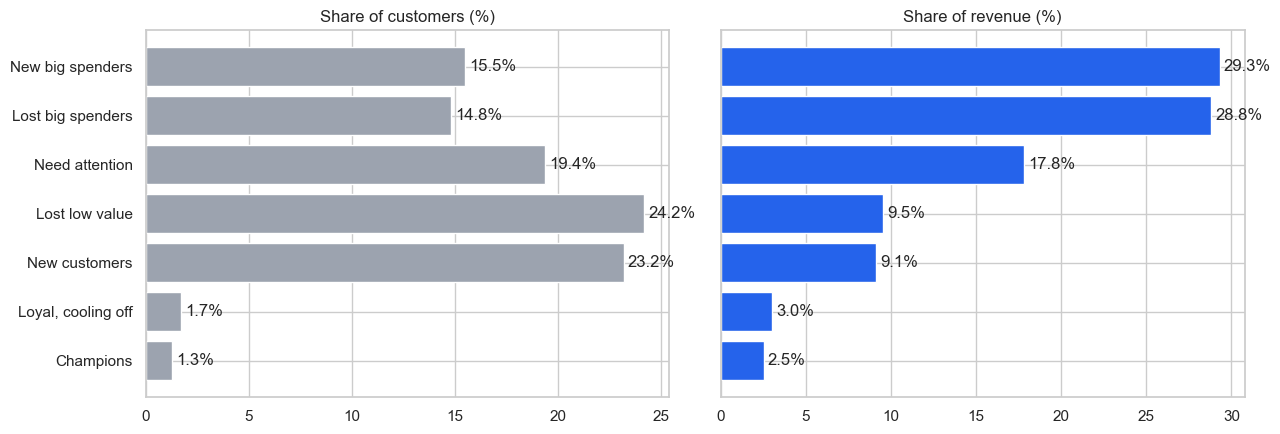

,segment,customers,customer_share_pct,revenue,revenue_share_pct,avg_revenue,avg_days_since_order,avg_orders
0,New big spenders,14441,15.50,"3,856,546.00",29.30,267.06,94.00,1.00
1,Lost big spenders,13745,14.80,"3,800,304.00",28.80,276.49,394.00,1.00
2,Need attention,18023,19.40,"2,344,789.00",17.80,130.10,222.00,1.00
3,Lost low value,22501,24.20,"1,254,650.00",9.50,55.76,395.00,1.00
4,New customers,21605,23.20,"1,199,383.00",9.10,55.51,92.00,1.00
5,"Loyal, cooling off",1594,1.70,"401,478.00",3.00,251.87,321.00,2.08
6,Champions,1195,1.30,"323,877.00",2.50,271.03,91.00,2.15


In [20]:
segments = run("rfm_segments")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ordered = segments.sort_values("revenue")
ax1.barh(ordered["segment"], ordered["customer_share_pct"], color=GREY)
ax1.set(title="Share of customers (%)")
ax2.barh(ordered["segment"], ordered["revenue_share_pct"], color=BLUE)
ax2.set(title="Share of revenue (%)")
for ax, col in [(ax1, "customer_share_pct"), (ax2, "revenue_share_pct")]:
    ax.bar_label(ax.containers[0], labels=[f"{v}%" for v in ordered[col]], padding=3)
plt.tight_layout()
plt.savefig(FIGURES + "rfm_segments.png", dpi=130)
plt.show()
segments

**Findings**

- **Two segments hold 58% of revenue with only 30% of customers:** New big spenders (15.5% of customers, 29.3% of revenue) and Lost big spenders (14.8% of customers, 28.8% of revenue).
- **New big spenders are the best opportunity.** 14,441 customers who spent about R$267 each and bought within the last six months. They are still within reach.
- **Lost big spenders** are 13,745 customers who spent about R$276 each but have not ordered for over a year on average.
- **Champions and Loyal customers together are only 3% of customers.** Each is worth about twice a typical customer.

In [21]:
run("revenue_concentration")

-- Q15. How much of revenue comes from the top customers?
-- NTILE(10) splits customers into ten equal groups by revenue.
-- Decile 1 is the top 10% of spenders.
WITH deciles AS (
    SELECT
        monetary,
        NTILE(10) OVER (ORDER BY monetary DESC, customer_unique_id) AS decile
    FROM v_customer_rfm
)
SELECT
    decile,
    COUNT(*)                                                     AS customers,
    ROUND(MIN(monetary), 2)                                      AS min_spend,
    ROUND(SUM(monetary), 0)                                      AS revenue,
    ROUND(100.0 * SUM(monetary) / SUM(SUM(monetary)) OVER (), 1) AS revenue_share_pct,
    ROUND(100.0 * SUM(SUM(monetary)) OVER (ORDER BY decile)
          / SUM(SUM(monetary)) OVER (), 1)                       AS cumulative_share_pct
FROM deciles
GROUP BY decile
ORDER BY decile;


,decile,customers,min_spend,revenue,revenue_share_pct,cumulative_share_pct
0,1,9311,279.99,"5,417,493.00",41.10,41.10
1,2,9311,179.90,"2,045,177.00",15.50,56.60
2,3,9311,139.00,"1,458,584.00",11.10,67.70
3,4,9311,109.90,"1,142,461.00",8.70,76.40
4,5,9310,89.70,"917,552.00",7.00,83.30
5,6,9310,69.90,"728,046.00",5.50,88.80
6,7,9310,52.98,"562,745.00",4.30,93.10
7,8,9310,39.90,"432,628.00",3.30,96.40
8,9,9310,25.98,"302,763.00",2.30,98.70
9,10,9310,0.85,"173,576.00",1.30,100.00


**Finding:** the **top 10% of customers bring in 41% of revenue**, and the top 30% bring in two thirds. A customer enters the top 10% by spending R$280 or more, which shows how much one large basket matters in this business.

In [22]:
run("segment_top_category")

-- Q16. What does each segment buy most?
-- ROW_NUMBER() ranks categories inside each segment; rank 1 is kept.
WITH segment_category AS (
    SELECT
        r.segment,
        i.product_category,
        SUM(i.price) AS revenue
    FROM v_order_items i
    JOIN v_orders o       USING (order_id)
    JOIN v_customer_rfm r USING (customer_unique_id)
    GROUP BY r.segment, i.product_category
),
ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY segment ORDER BY revenue DESC) AS category_rank,
           100.0 * revenue / SUM(revenue) OVER (PARTITION BY segment)     AS share_of_segment
    FROM segment_category
)
SELECT
    segment,
    product_category        AS top_category,
    ROUND(revenue, 0)       AS revenue,
    ROUND(share_of_segment, 1) AS share_of_segment_pct
FROM ranked
WHERE category_rank = 1
ORDER BY revenue DESC;


,segment,top_category,revenue,share_of_segment_pct
0,New big spenders,health_beauty,"441,700.00",11.50
1,Lost big spenders,watches_gifts,"372,723.00",9.80
2,Need attention,health_beauty,"213,629.00",9.10
3,Lost low value,bed_bath_table,"148,190.00",11.80
4,New customers,bed_bath_table,"131,134.00",10.90
5,"Loyal, cooling off",bed_bath_table,"59,642.00",14.90
6,Champions,bed_bath_table,"35,197.00",10.90


Big spenders buy health and beauty, and watches and gifts. Lower spenders and repeat customers buy bed, bath and table products. That suggests different offers for different segments.

## 5. Delivery and reviews

-- Q17. How do review scores differ between late and on-time orders?
SELECT
    CASE WHEN delivered_late THEN 'Late' ELSE 'On time' END      AS delivery,
    COUNT(*)                                                     AS orders,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)           AS share_pct,
    ROUND(AVG(delivery_days), 1)                                 AS avg_delivery_days,
    ROUND(AVG(review_score), 2)                                  AS avg_review_score,
    ROUND(100.0 * COUNT(*) FILTER (WHERE review_score <= 2)
          / COUNT(review_score), 1)                              AS bad_review_pct
FROM v_orders
WHERE delivered_late IS NOT NULL
GROUP BY delivered_late
ORDER BY delivered_late;


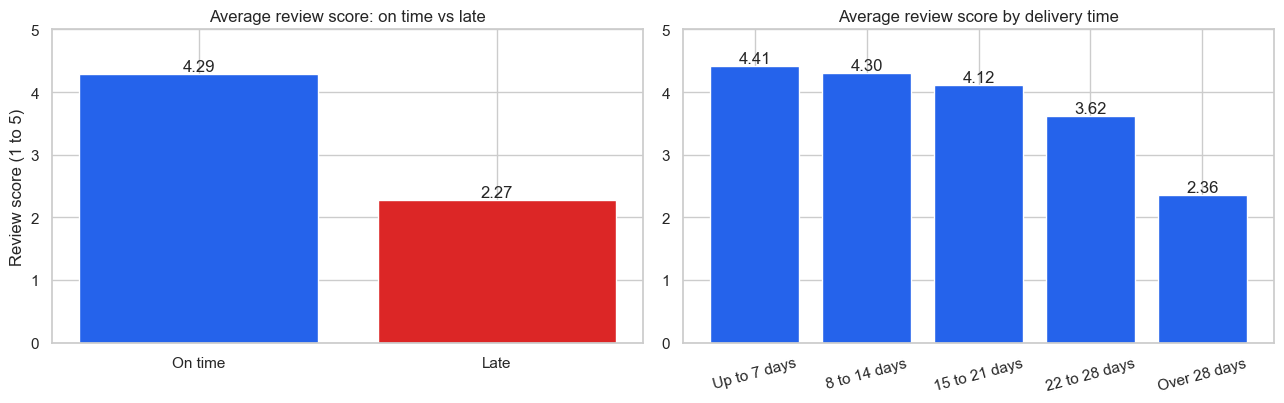

,delivery,orders,share_pct,avg_delivery_days,avg_review_score,bad_review_pct
0,On time,89672,93.20,10.90,4.29,9.20
1,Late,6531,6.80,33.90,2.27,62.40


,delivery_time,orders,share_pct,avg_review_score,bad_review_pct
0,1. Up to 7 days,30660,31.90,4.41,7.60
1,2. 8 to 14 days,37899,39.40,4.30,9.10
2,3. 15 to 21 days,16110,16.70,4.12,12.20
3,4. 22 to 28 days,6324,6.60,3.62,23.80
4,5. Over 28 days,5210,5.40,2.36,60.00


In [23]:
late = run("late_vs_on_time")
bands = run("review_by_delivery_time", show_sql=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
b1 = ax1.bar(late["delivery"], late["avg_review_score"], color=[BLUE, RED])
ax1.bar_label(b1, fmt="%.2f")
ax1.set(title="Average review score: on time vs late", ylabel="Review score (1 to 5)", ylim=(0, 5))
b2 = ax2.bar(bands["delivery_time"].str[3:], bands["avg_review_score"], color=BLUE)
ax2.bar_label(b2, fmt="%.2f")
ax2.set(title="Average review score by delivery time", ylim=(0, 5))
ax2.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(FIGURES + "delivery_vs_reviews.png", dpi=130)
plt.show()
display(late, bands)

**Findings**

- Only 6.8% of orders arrive late, but the effect is severe: late orders average **2.27 stars against 4.29** for on-time orders.
- **62% of late orders get a 1 or 2 star review**, against 9% of on-time orders.
- Reviews hold up well for the first three weeks (4.4 falling to 4.1). After 21 days they drop sharply: 3.6 for 22 to 28 days and 2.4 beyond that.

This is a correlation, not proof of cause. Late orders may differ in other ways (bulky products, remote regions). But the size and consistency of the gap make delivery the most likely driver.

In [24]:
run("delivery_by_state")

-- Q19. Which states have the slowest and latest deliveries?
-- HAVING keeps only states with enough orders for a stable figure.
SELECT
    customer_state,
    COUNT(*)                                                     AS orders,
    ROUND(AVG(delivery_days), 1)                                 AS avg_delivery_days,
    ROUND(100.0 * AVG(delivered_late::int), 1)                   AS late_pct,
    ROUND(AVG(review_score), 2)                                  AS avg_review_score,
    ROUND(AVG(freight), 2)                                       AS avg_freight
FROM v_orders
GROUP BY customer_state
HAVING COUNT(*) >= 500
ORDER BY late_pct DESC;


,customer_state,orders,avg_delivery_days,late_pct,avg_review_score,avg_freight
0,MA,713,21.50,17.50,3.83,42.78
1,CE,1273,21.20,13.80,3.94,36.48
2,BA,3253,19.30,12.20,3.93,29.97
3,RJ,12310,15.20,12.10,3.97,23.96
4,PA,942,23.70,11.30,3.91,39.66
5,ES,1992,15.70,10.70,4.08,24.54
6,PB,516,20.40,10.50,4.07,48.89
7,MS,701,15.50,9.70,4.16,27.02
8,PE,1587,18.40,9.60,4.08,35.78
9,SC,3537,14.90,8.20,4.13,24.84


**Finding:** late delivery is a regional problem.

- North-eastern states are worst: Maranhão (MA) 17.5% late, Ceará (CE) 13.8%, Bahia (BA) 12.2%.
- **Rio de Janeiro (RJ) stands out.** It is the second largest market with 12,310 orders, yet 12.1% arrive late, nearly three times the rate in São Paulo (4.5%). Fixing RJ would help more customers than fixing any other state.

-- Q20. Is delivery getting better or worse over time?
SELECT
    order_month,
    COUNT(*)                                                     AS orders,
    ROUND(AVG(delivery_days), 1)                                 AS avg_delivery_days,
    ROUND(100.0 * AVG(delivered_late::int), 1)                   AS late_pct,
    ROUND(AVG(review_score), 2)                                  AS avg_review_score
FROM v_orders
GROUP BY order_month
ORDER BY order_month;


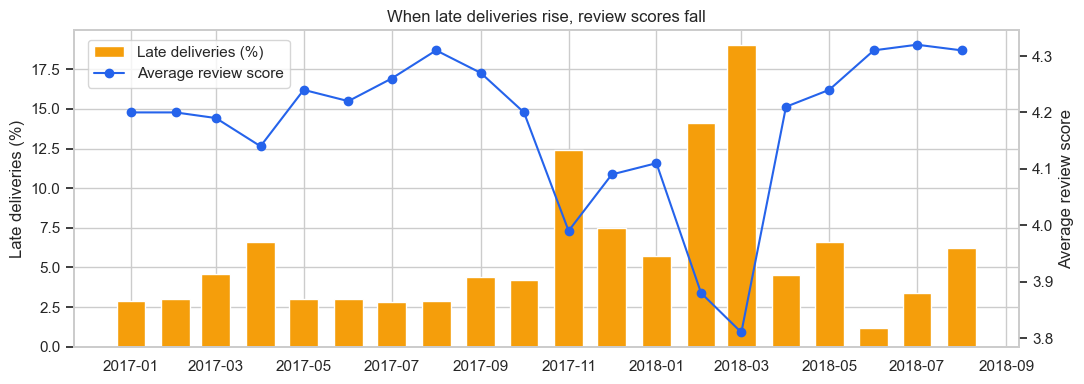

In [25]:
trend = run("monthly_delivery_trend")
trend["order_month"] = pd.to_datetime(trend["order_month"])
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(trend["order_month"], trend["late_pct"], width=20, color=AMBER, label="Late deliveries (%)")
ax1.set_ylabel("Late deliveries (%)")
ax2 = ax1.twinx()
ax2.plot(trend["order_month"], trend["avg_review_score"], color=BLUE, marker="o", label="Average review score")
ax2.set_ylabel("Average review score")
ax2.grid(False)
ax1.set_title("When late deliveries rise, review scores fall")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.9))
plt.tight_layout()
plt.savefig(FIGURES + "late_trend.png", dpi=130)
plt.show()

**Finding:** late deliveries spiked twice: **November 2017 (12.4%)**, when Black Friday volume overwhelmed logistics, and **February to March 2018 (14% and 19%)**. Review scores fell in the same months, to 3.8. By July 2018 the average delivery time was under 9 days.

In [26]:
run("lowest_rated_categories")

-- Q21. Which large categories have the unhappiest customers?
-- An order can hold items from several categories, so the order's
-- review is counted once for each category in it.
SELECT
    i.product_category,
    COUNT(DISTINCT i.order_id)                                   AS orders,
    ROUND(AVG(o.review_score), 2)                                AS avg_review_score,
    ROUND(100.0 * AVG(o.delivered_late::int), 1)                 AS late_pct
FROM (SELECT DISTINCT order_id, product_category FROM v_order_items) i
JOIN v_orders o USING (order_id)
GROUP BY i.product_category
HAVING COUNT(DISTINCT i.order_id) >= 1000
ORDER BY avg_review_score
LIMIT 8;


,product_category,orders,avg_review_score,late_pct
0,office_furniture,1248,3.65,8.10
1,bed_bath_table,9267,4.00,7.40
2,unknown,1390,4.01,7.30
3,telephony,4086,4.05,7.10
4,furniture_decor,6258,4.06,7.20
5,computers_accessories,6518,4.08,6.40
6,baby,2800,4.10,8.10
7,electronics,2516,4.12,7.60


**Finding:** office furniture has the lowest rating of any large category (3.65). Its late rate is not unusually high, so the cause is probably the product itself (assembly, damage in transit, items arriving in separate parcels) and worth investigating.

## 6. Findings and recommendations

### Summary of findings

| # | Finding | Evidence |
|---|---|---|
| 1 | Growth has stalled | 2018 monthly revenue flat at R$826 to R$978 thousand; year-on-year growth fell from 727% to 51% |
| 2 | Customers do not come back | 97% ordered once; returning customers are about 3% of monthly revenue |
| 3 | A bad first order is not the cause | Repeat rate is about 3% for every first-order review score |
| 4 | Customers who return do so within a month | 51% of second orders come within 30 days |
| 5 | Revenue is concentrated | Top 10% of customers = 41% of revenue; 18 of 74 categories = 80%; SP = 38% |
| 6 | Late delivery destroys satisfaction | 2.27 stars when late against 4.29 on time; 62% bad reviews against 9% |
| 7 | Late delivery is regional and seasonal | RJ 12.1% late against SP 4.5%; spikes in Nov 2017 and Feb to Mar 2018 |

### Recommendations

1. **Make retention the priority.** With new-customer growth slowing, a second purchase is the cheapest revenue available. Even moving the repeat rate from 3% to 5% would add about 1,900 repeat customers.
2. **Send a follow-up offer within 30 days of the first order.** That is when customers who return actually do so. Start with the 14,441 New big spenders.
3. **Run a win-back campaign for Lost big spenders.** 13,745 customers who each spent about R$276 and have gone quiet.
4. **Fix delivery in Rio de Janeiro first.** It is the second largest market and has nearly three times São Paulo's late rate.
5. **Prepare logistics for Black Friday.** November 2017 brought the highest revenue and a late rate that tripled, followed by lower reviews.
6. **Promise realistic delivery dates.** A customer is far more upset by a missed date than by a longer one that is met.

### Limitations

- The data covers 20 months, so there is only one Black Friday and no full second year for seasonality.
- Relationships such as late delivery and low reviews are correlations. They suggest a cause but do not prove one.
- The data has no marketing spend, costs or margins, so revenue is used throughout and profitability is not measured.
- Same-day second orders are counted as repeat purchases, which probably overstates the repeat rate.